# Ulaanbaatar Air Quality Advisor

**Question:** When is Ulaanbaatar's air worst, how much do cold weather, wind and the heating season matter, and should I go outside or wear a mask today?

**Data (two real, free sources that we merge):**
1. **Open-Meteo Air Quality API**: hourly PM2.5, PM10 and NO2 for Ulaanbaatar. These values come from an atmosphere model (CAMS, Copernicus), **not from sensors on the ground**.
2. **Open-Meteo Historical Weather API**: hourly temperature, humidity, wind, rain and snow (ERA5 reanalysis).

Both are free and need no API key. https://open-meteo.com

**How to run:** you need internet the first time. The notebook downloads the data once and saves two CSV files (`ub_air.csv` and `ub_weather.csv`) in the same folder. Next time it uses the saved files.

In [1]:
%pip install requests pandas numpy matplotlib scikit-learn

Note: you may need to restart the kernel to use updated packages.


In [2]:
import os
import time
import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, r2_score

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)
plt.rcParams["figure.figsize"] = (11, 5)

## 1. Settings and download
If the download says the start date is not available, try a later `START_DATE`.
Weather data arrives a few days late, so the end date is 7 days before today.

In [3]:
# ---------------- SETTINGS ----------------
LAT, LON = 47.92, 106.92                 # Ulaanbaatar
TIMEZONE = "Asia/Ulaanbaatar"
START_DATE = "2023-01-01"
END_DATE = (pd.Timestamp.today() - pd.Timedelta(days=7)).strftime("%Y-%m-%d")
FORCE_DOWNLOAD = False                   # True = download again even if the CSV files exist
AIR_FILE, WEATHER_FILE = "ub_air.csv", "ub_weather.csv"
# ------------------------------------------

AIR_URL = "https://air-quality-api.open-meteo.com/v1/air-quality"
WEATHER_URL = "https://archive-api.open-meteo.com/v1/archive"
AIR_VARS = ["pm10", "pm2_5", "nitrogen_dioxide"]
WEATHER_VARS = ["temperature_2m", "relative_humidity_2m", "wind_speed_10m", "precipitation", "snowfall"]


def fetch_hourly(url, variables, start, end):
    # downloads the data in 6-month pieces and joins them
    frames = []
    cur = pd.Timestamp(start)
    last = pd.Timestamp(end)
    while cur <= last:
        chunk_end = min(cur + pd.DateOffset(months=6) - pd.Timedelta(days=1), last)
        params = {"latitude": LAT, "longitude": LON, "timezone": TIMEZONE,
                  "start_date": cur.strftime("%Y-%m-%d"),
                  "end_date": chunk_end.strftime("%Y-%m-%d"),
                  "hourly": ",".join(variables)}
        r = None
        for attempt in range(4):
            r = requests.get(url, params=params, timeout=90)
            if r.status_code == 200:
                break
            time.sleep(5 * (attempt + 1))
        if r.status_code != 200:
            raise RuntimeError(f"Download failed ({r.status_code}) for {params['start_date']} to "
                               f"{params['end_date']}: {r.text[:200]}")
        frames.append(pd.DataFrame(r.json()["hourly"]))
        print("  downloaded", params["start_date"], "to", params["end_date"])
        cur = chunk_end + pd.Timedelta(days=1)
        time.sleep(1)
    return pd.concat(frames, ignore_index=True)


if FORCE_DOWNLOAD or not (os.path.exists(AIR_FILE) and os.path.exists(WEATHER_FILE)):
    print("Downloading air quality data...")
    fetch_hourly(AIR_URL, AIR_VARS, START_DATE, END_DATE).to_csv(AIR_FILE, index=False)
    print("Downloading weather data...")
    fetch_hourly(WEATHER_URL, WEATHER_VARS, START_DATE, END_DATE).to_csv(WEATHER_FILE, index=False)
    print("Saved:", AIR_FILE, "and", WEATHER_FILE)
else:
    print("Found saved files, skipping the download:", AIR_FILE, "and", WEATHER_FILE)

  downloaded 2023-01-01 to 2023-06-30
  downloaded 2023-07-01 to 2023-12-31
  downloaded 2024-01-01 to 2024-06-30
  downloaded 2024-07-01 to 2024-12-31
  downloaded 2025-01-01 to 2025-06-30
  downloaded 2025-07-01 to 2025-12-31
  downloaded 2026-01-01 to 2026-06-30
  downloaded 2026-07-01 to 2026-11-02
  downloaded 2023-01-01 to 2023-06-30
  downloaded 2023-07-01 to 2023-12-31
  downloaded 2024-01-01 to 2024-06-30
  downloaded 2024-07-01 to 2024-12-31
  downloaded 2025-01-01 to 2025-06-30
  downloaded 2025-07-01 to 2025-12-31
  downloaded 2026-01-01 to 2026-06-30
  downloaded 2026-07-01 to 2026-11-02
Saved: ub_air.csv and ub_weather.csv


## 2. Load and check the data

In [4]:
air = pd.read_csv(AIR_FILE)
weather = pd.read_csv(WEATHER_FILE)
print("Air quality:", air.shape, "| Weather:", weather.shape)
air.head()

Air quality: (33648, 4) | Weather: (33648, 6)


,time,pm10,pm2_5,nitrogen_dioxide
0,2023-01-01T00:00,35.4,24.7,89.8
1,2023-01-01T01:00,30.6,21.4,89.0
2,2023-01-01T02:00,28.5,19.9,88.1
3,2023-01-01T03:00,24.6,17.2,87.4
4,2023-01-01T04:00,23.7,16.6,86.6


In [5]:
print(weather.head())
print()
print("Missing values in air data:")
print(air.isna().sum())
print()
print("Missing values in weather data:")
print(weather.isna().sum())
print()
air.describe().round(1)

               time  temperature_2m  relative_humidity_2m  wind_speed_10m  precipitation  snowfall
0  2023-01-01T00:00           -19.6                    86             1.3            0.0       0.0
1  2023-01-01T01:00           -19.9                    87             1.3            0.0       0.0
2  2023-01-01T02:00           -20.4                    89             1.5            0.0       0.0
3  2023-01-01T03:00           -20.8                    80             3.0            0.0       0.0
4  2023-01-01T04:00           -21.1                    80             2.6            0.0       0.0

Missing values in air data:
time                0
pm10                0
pm2_5               0
nitrogen_dioxide    0
dtype: int64

Missing values in weather data:
time                    0
temperature_2m          0
relative_humidity_2m    0
wind_speed_10m          0
precipitation           0
snowfall                0
dtype: int64



,pm10,pm2_5,nitrogen_dioxide
count,33648.0,33648.0,33648.0
mean,27.1,20.9,16.4
std,26.5,23.4,16.6
min,0.1,0.1,0.0
25%,8.9,6.2,4.2
50%,17.9,12.2,10.0
75%,35.5,25.4,23.0
max,197.9,195.6,109.2


## 3. Clean and merge the data
- turn the `time` text into real dates
- remove duplicate hours and impossible values (negative concentrations or humidity above 100)
- fill short gaps (up to 3 hours) in the weather
- **merge** the air quality and weather tables on the hour
- give the columns clear names

In [6]:
air["time"] = pd.to_datetime(air["time"])
weather["time"] = pd.to_datetime(weather["time"])

print("Duplicate hours (air, weather):", air["time"].duplicated().sum(), weather["time"].duplicated().sum())
air = air.drop_duplicates(subset="time").sort_values("time")
weather = weather.drop_duplicates(subset="time").sort_values("time")

# impossible values become missing
for c in ["pm10", "pm2_5", "nitrogen_dioxide"]:
    air.loc[air[c] < 0, c] = np.nan
weather.loc[weather["relative_humidity_2m"] > 100, "relative_humidity_2m"] = np.nan
weather.loc[weather["wind_speed_10m"] < 0, "wind_speed_10m"] = np.nan

# short gaps in the weather
wcols = [c for c in weather.columns if c != "time"]
weather[wcols] = weather[wcols].interpolate(limit=3)

# merge the two sources on the hour
data = air.merge(weather, on="time", how="inner")
data = data.rename(columns={"pm2_5": "pm25", "temperature_2m": "temp_c", "relative_humidity_2m": "humidity",
                            "wind_speed_10m": "wind_kmh", "nitrogen_dioxide": "no2"})
rows_before = len(data)
data = data.dropna(subset=["pm25"]).reset_index(drop=True)

print("Rows after merge:", rows_before, "| rows with a PM2.5 value:", len(data))
print("Date range:", data["time"].min(), "to", data["time"].max())
data.head()

Duplicate hours (air, weather): 0 0
Rows after merge: 33648 | rows with a PM2.5 value: 33648
Date range: 2023-01-01 00:00:00 to 2026-11-02 23:00:00


,time,pm10,pm25,no2,temp_c,humidity,wind_kmh,precipitation,snowfall
0,2023-01-01 00:00:00,35.4,24.7,89.8,-19.6,86.0,1.3,0.0,0.0
1,2023-01-01 01:00:00,30.6,21.4,89.0,-19.9,87.0,1.3,0.0,0.0
2,2023-01-01 02:00:00,28.5,19.9,88.1,-20.4,89.0,1.5,0.0,0.0
3,2023-01-01 03:00:00,24.6,17.2,87.4,-20.8,80.0,3.0,0.0,0.0
4,2023-01-01 04:00:00,23.7,16.6,86.6,-21.1,80.0,2.6,0.0,0.0


## 4. New columns
hour, weekday, month, year, season, **heating season** (October to April), temperature band, wind band, and a daily table with an air quality category.

The categories use the US EPA scale for the 24-hour average PM2.5 (µg/m³). The WHO guideline for 24 hours is 15 µg/m³.

In [7]:
CATS = ["Good", "Moderate", "Unhealthy for sensitive", "Unhealthy", "Very unhealthy", "Hazardous"]
CAT_COLORS = ["green", "gold", "orange", "red", "purple", "maroon"]
PM_BINS = [-1, 9.0, 35.4, 55.4, 125.4, 225.4, 1e6]
WHO_DAILY = 15

data["hour"] = data["time"].dt.hour
data["weekday"] = data["time"].dt.day_name()
data["month"] = data["time"].dt.month
data["year"] = data["time"].dt.year
data["season"] = data["month"].map({12: "Winter", 1: "Winter", 2: "Winter", 3: "Spring", 4: "Spring",
                                    5: "Spring", 6: "Summer", 7: "Summer", 8: "Summer",
                                    9: "Autumn", 10: "Autumn", 11: "Autumn"})
data["heating"] = data["month"].isin([10, 11, 12, 1, 2, 3, 4])
data["temp_band"] = pd.cut(data["temp_c"], [-60, -20, -10, 0, 10, 60],
                           labels=["below -20", "-20 to -10", "-10 to 0", "0 to 10", "above 10"])
data["wind_band"] = pd.cut(data["wind_kmh"], [-1, 5, 10, 20, 500],
                           labels=["below 5", "5-10", "10-20", "above 20"])

# daily table (keep days with at least 18 hours of data)
daily = data.set_index("time").resample("D").agg(
    pm25=("pm25", "mean"), pm10=("pm10", "mean"), temp_c=("temp_c", "mean"),
    wind_kmh=("wind_kmh", "mean"), humidity=("humidity", "mean"), hours=("pm25", "count"))
daily = daily[daily["hours"] >= 18].copy()
daily["month"] = daily.index.month
daily["year"] = daily.index.year
daily["heating"] = daily["month"].isin([10, 11, 12, 1, 2, 3, 4])
daily["category"] = pd.cut(daily["pm25"], PM_BINS, labels=CATS)
daily["over_who"] = daily["pm25"] > WHO_DAILY

print("Days in the daily table:", len(daily))
daily.head()

Days in the daily table: 1402


,pm25,pm10,temp_c,wind_kmh,humidity,hours,month,year,heating,category,over_who
time,,,,,,,,,,,
2023-01-01,29.466667,42.120833,-20.908333,3.383333,81.666667,24,1,2023,True,Moderate,True
2023-01-02,61.804167,88.408333,-21.154167,4.641667,74.958333,24,1,2023,True,Unhealthy,True
2023-01-03,55.387500,79.187500,-21.154167,5.575000,80.875000,24,1,2023,True,Unhealthy for sensitive,True
2023-01-04,46.062500,66.100000,-20.437500,5.908333,73.500000,24,1,2023,True,Unhealthy for sensitive,True
2023-01-05,46.537500,66.641667,-17.570833,6.045833,73.000000,24,1,2023,True,Unhealthy for sensitive,True


## 5. Key numbers

In [8]:
heat = daily[daily["heating"]]["pm25"].mean()
nonheat = daily[~daily["heating"]]["pm25"].mean()
worst_month = daily.groupby("month")["pm25"].mean().idxmax()
worst_hour = data.groupby("hour")["pm25"].mean().idxmax()

print("Average PM2.5 in the heating season (Oct-Apr):     %.1f ug/m3" % heat)
print("Average PM2.5 outside the heating season (May-Sep): %.1f ug/m3" % nonheat)
print("The heating season is %.1f times worse." % (heat / nonheat))
print()
print("Days above the WHO guideline (15 ug/m3): %.0f%% of all days" % (daily["over_who"].mean() * 100))
print("Days rated Unhealthy or worse:           %.0f%% of all days" % ((daily["pm25"] > 55.4).mean() * 100))
print("Worst month on average:", worst_month, "| worst hour of the day on average:", worst_hour)
print()
print(daily["category"].value_counts().reindex(CATS))

Average PM2.5 in the heating season (Oct-Apr):     29.2 ug/m3
Average PM2.5 outside the heating season (May-Sep): 10.2 ug/m3
The heating season is 2.9 times worse.

Days above the WHO guideline (15 ug/m3): 43% of all days
Days rated Unhealthy or worse:           8% of all days
Worst month on average: 12 | worst hour of the day on average: 23

category
Good                       347
Moderate                   818
Unhealthy for sensitive    126
Unhealthy                  111
Very unhealthy               0
Hazardous                    0
Name: count, dtype: int64


## 6. Charts

### Chart 1: When is the air worst? (average PM2.5 by month and hour)

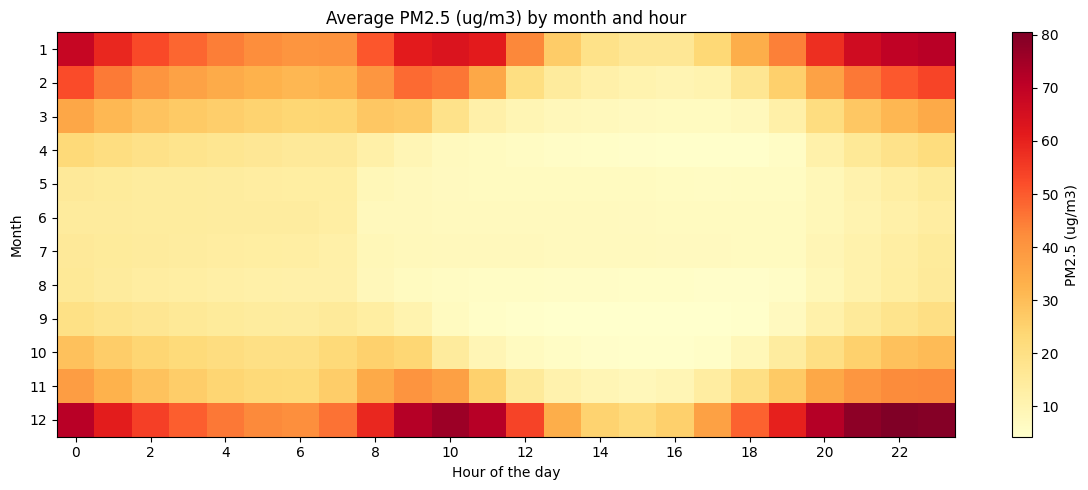

In [9]:
pivot = data.pivot_table(index="month", columns="hour", values="pm25", aggfunc="mean")

fig, ax = plt.subplots(figsize=(12, 5))
im = ax.imshow(pivot.values, cmap="YlOrRd", aspect="auto")
ax.set_xticks(range(0, 24, 2)); ax.set_xticklabels(range(0, 24, 2))
ax.set_yticks(range(len(pivot.index))); ax.set_yticklabels(pivot.index)
ax.set_xlabel("Hour of the day"); ax.set_ylabel("Month")
ax.set_title("Average PM2.5 (ug/m3) by month and hour")
fig.colorbar(im, label="PM2.5 (ug/m3)")
plt.tight_layout(); plt.show()

### Chart 2: Daily PM2.5 over time (heating season shaded)

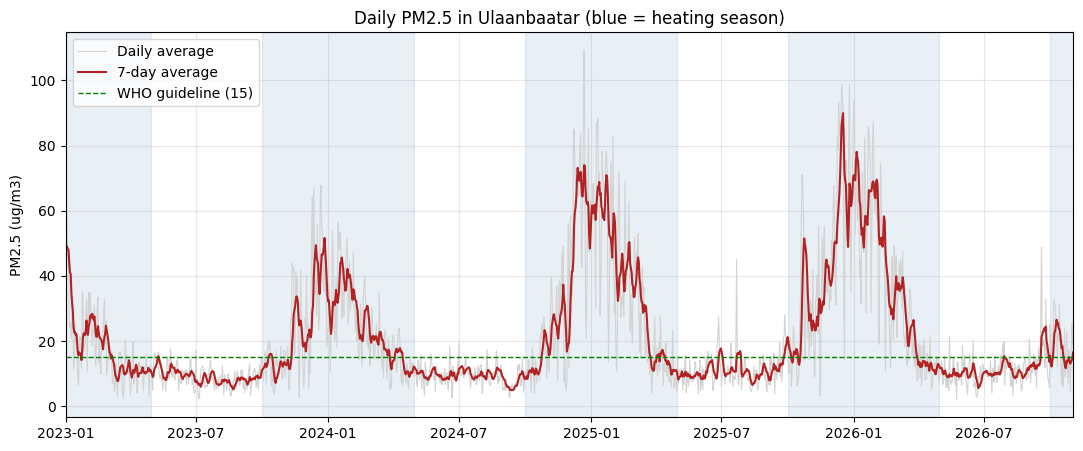

In [10]:
fig, ax = plt.subplots(figsize=(13, 5))
ax.plot(daily.index, daily["pm25"], color="lightgray", linewidth=0.8, label="Daily average")
ax.plot(daily.index, daily["pm25"].rolling(7, min_periods=3).mean(), color="firebrick", linewidth=1.5,
        label="7-day average")
for y in range(daily.index.min().year - 1, daily.index.max().year + 1):
    ax.axvspan(pd.Timestamp(y, 10, 1), pd.Timestamp(y + 1, 4, 30), color="steelblue", alpha=0.12)
ax.axhline(WHO_DAILY, color="green", linestyle="--", linewidth=1, label="WHO guideline (15)")
ax.set_xlim(daily.index.min(), daily.index.max())
ax.set_title("Daily PM2.5 in Ulaanbaatar (blue = heating season)")
ax.set_ylabel("PM2.5 (ug/m3)"); ax.legend(); ax.grid(alpha=0.3)
plt.show()

### Chart 3: Share of days in each air quality category, by month

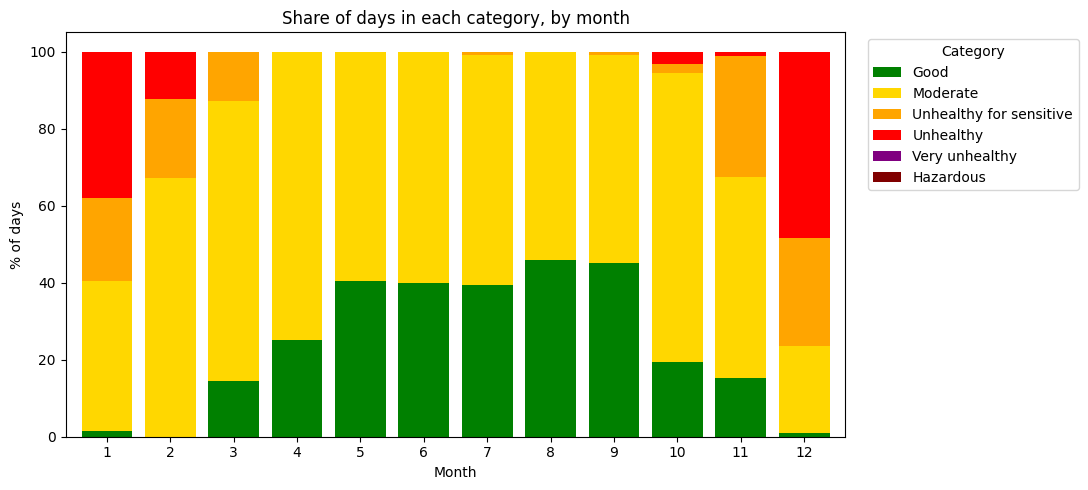

In [11]:
share = pd.crosstab(daily["month"], daily["category"], normalize="index").reindex(columns=CATS, fill_value=0) * 100
share.plot.bar(stacked=True, color=CAT_COLORS, figsize=(11, 5), width=0.8)
plt.title("Share of days in each category, by month")
plt.xlabel("Month"); plt.ylabel("% of days"); plt.xticks(rotation=0)
plt.legend(title="Category", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout(); plt.show()

### Chart 4: Temperature vs PM2.5

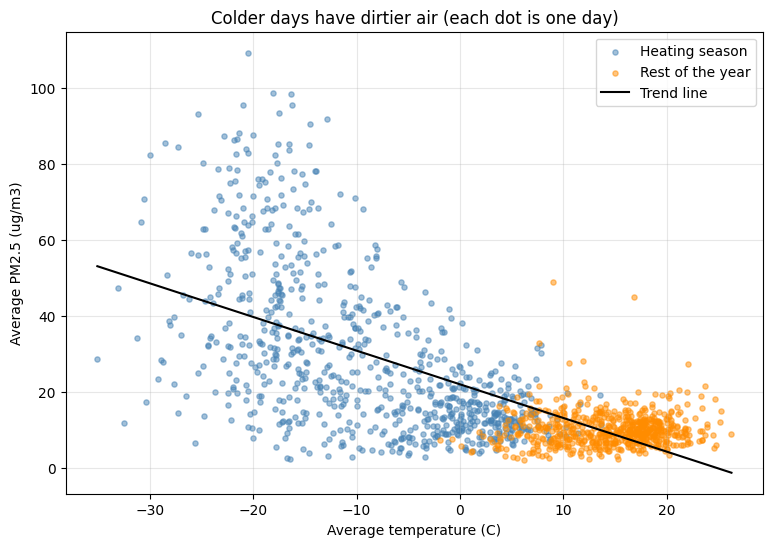

Correlation between temperature and PM2.5: -0.67
Each 10 C colder adds about 9 ug/m3 of PM2.5 on average.


In [12]:
d = daily.dropna(subset=["temp_c", "pm25"])
plt.figure(figsize=(9, 6))
plt.scatter(d.loc[d["heating"], "temp_c"], d.loc[d["heating"], "pm25"], s=14, alpha=0.5,
            color="steelblue", label="Heating season")
plt.scatter(d.loc[~d["heating"], "temp_c"], d.loc[~d["heating"], "pm25"], s=14, alpha=0.5,
            color="darkorange", label="Rest of the year")
slope, intercept = np.polyfit(d["temp_c"], d["pm25"], 1)
xs = np.linspace(d["temp_c"].min(), d["temp_c"].max(), 50)
plt.plot(xs, slope * xs + intercept, color="black", linewidth=1.5, label="Trend line")
plt.title("Colder days have dirtier air (each dot is one day)")
plt.xlabel("Average temperature (C)"); plt.ylabel("Average PM2.5 (ug/m3)")
plt.legend(); plt.grid(alpha=0.3); plt.show()
print("Correlation between temperature and PM2.5: %.2f" % d["temp_c"].corr(d["pm25"]))
print("Each 10 C colder adds about %.0f ug/m3 of PM2.5 on average." % (-slope * 10))

### Chart 5: Does wind clean the air? (PM2.5 by wind speed)

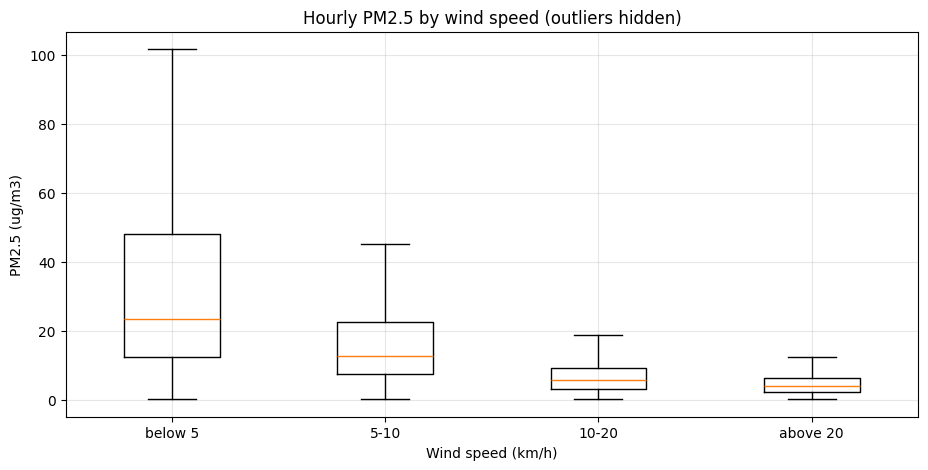

In [13]:
bands = ["below 5", "5-10", "10-20", "above 20"]
groups = [data.loc[data["wind_band"] == b, "pm25"].dropna() for b in bands]
plt.boxplot(groups, showfliers=False)
plt.xticks(range(1, len(bands) + 1), bands)
plt.title("Hourly PM2.5 by wind speed (outliers hidden)")
plt.xlabel("Wind speed (km/h)"); plt.ylabel("PM2.5 (ug/m3)"); plt.grid(alpha=0.3)
plt.show()

### Chart 6: A day in the life of the air (average PM2.5 by hour)

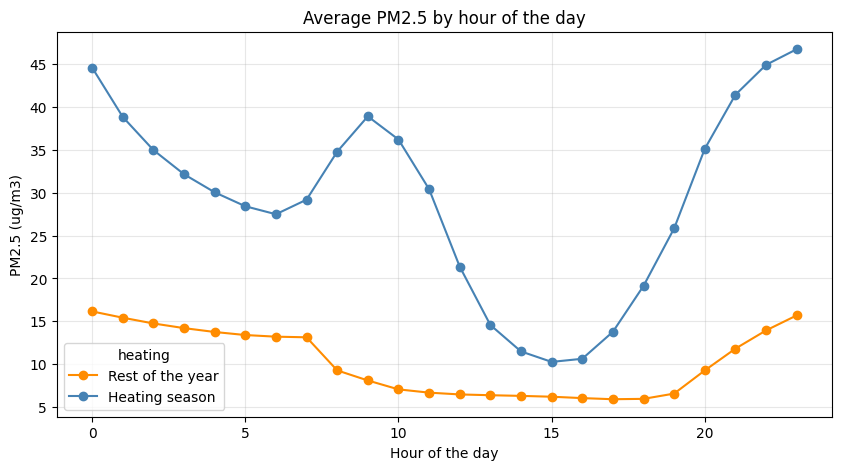

In [14]:
by_hour = data.groupby(["hour", "heating"])["pm25"].mean().unstack()
by_hour = by_hour.rename(columns={True: "Heating season", False: "Rest of the year"})
by_hour.plot(marker="o", figsize=(10, 5), color=["darkorange", "steelblue"][:by_hour.shape[1]])
plt.title("Average PM2.5 by hour of the day")
plt.xlabel("Hour of the day"); plt.ylabel("PM2.5 (ug/m3)"); plt.grid(alpha=0.3); plt.show()

### Chart 7: Is it getting better? (heating season average by year)

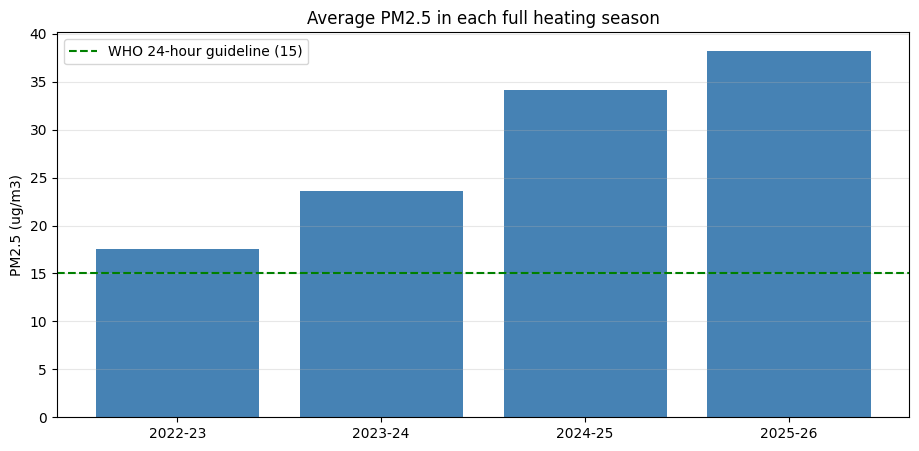

,pm25,days
season_start,,
2022,17.6,120
2023,23.6,213
2024,34.2,212
2025,38.3,212


In [15]:
hs = daily[daily["heating"]].copy()
# a heating season starts in October, so months 1-4 belong to the season that started the year before
hs["season_start"] = np.where(hs["month"] >= 10, hs["year"], hs["year"] - 1)
by_season = hs.groupby("season_start").agg(pm25=("pm25", "mean"), days=("pm25", "count"))
by_season = by_season[by_season["days"] >= 90]
labels = [f"{y}-{str(y + 1)[2:]}" for y in by_season.index]

plt.bar(labels, by_season["pm25"], color="steelblue")
plt.axhline(WHO_DAILY, color="green", linestyle="--", label="WHO 24-hour guideline (15)")
plt.title("Average PM2.5 in each full heating season")
plt.ylabel("PM2.5 (ug/m3)"); plt.legend(); plt.grid(axis="y", alpha=0.3); plt.show()
by_season.round(1)

## 7. Model: can we predict PM2.5 from the weather?
We predict the logarithm of PM2.5 (because PM2.5 has a few very large values) from temperature, wind, humidity, rain, the heating season and the hour of the day.
We train on the **first 75% of the time** and test on the **last 25%**, as we would predict the future in real life.
We compare three models: a simple average (baseline), linear regression, and random forest.

In [16]:
m = data.copy()
m["precipitation"] = m["precipitation"].fillna(0)
m = m.dropna(subset=["temp_c", "wind_kmh", "humidity"]).sort_values("time")
m["is_heating"] = m["heating"].astype(int)
m["hour_sin"] = np.sin(2 * np.pi * m["hour"] / 24)
m["hour_cos"] = np.cos(2 * np.pi * m["hour"] / 24)

FEATURES = ["temp_c", "wind_kmh", "humidity", "precipitation", "is_heating", "hour_sin", "hour_cos"]
split = int(len(m) * 0.75)
train, test = m.iloc[:split], m.iloc[split:]
y_train = np.log1p(train["pm25"])

lin = LinearRegression().fit(train[FEATURES], y_train)
rf = RandomForestRegressor(n_estimators=150, max_depth=12, min_samples_leaf=5,
                           random_state=42, n_jobs=-1).fit(train[FEATURES], y_train)

pred = {
    "Baseline (average)": np.full(len(test), train["pm25"].mean()),
    "Linear regression": np.expm1(lin.predict(test[FEATURES])),
    "Random forest": np.expm1(rf.predict(test[FEATURES])),
}
rows = []
for name, p in pred.items():
    rows.append({"Model": name,
                 "Average error (ug/m3)": round(mean_absolute_error(test["pm25"], p), 1),
                 "R2": round(r2_score(test["pm25"], p), 2)})
print("Training period:", train["time"].min().date(), "to", train["time"].max().date())
print("Test period:    ", test["time"].min().date(), "to", test["time"].max().date())
pd.DataFrame(rows)

Training period: 2023-01-01 to 2025-11-17
Test period:     2025-11-17 to 2026-11-02


,Model,Average error (ug/m3),R2
0,Baseline (average),20.3,-0.06
1,Linear regression,13.6,0.37
2,Random forest,11.2,0.58


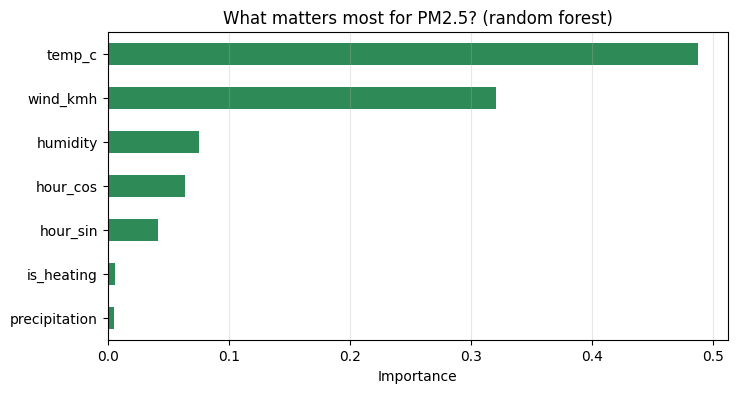

In [17]:
imp = pd.Series(rf.feature_importances_, index=FEATURES).sort_values()
imp.plot.barh(color="seagreen", figsize=(8, 4))
plt.title("What matters most for PM2.5? (random forest)")
plt.xlabel("Importance"); plt.grid(axis="x", alpha=0.3); plt.show()

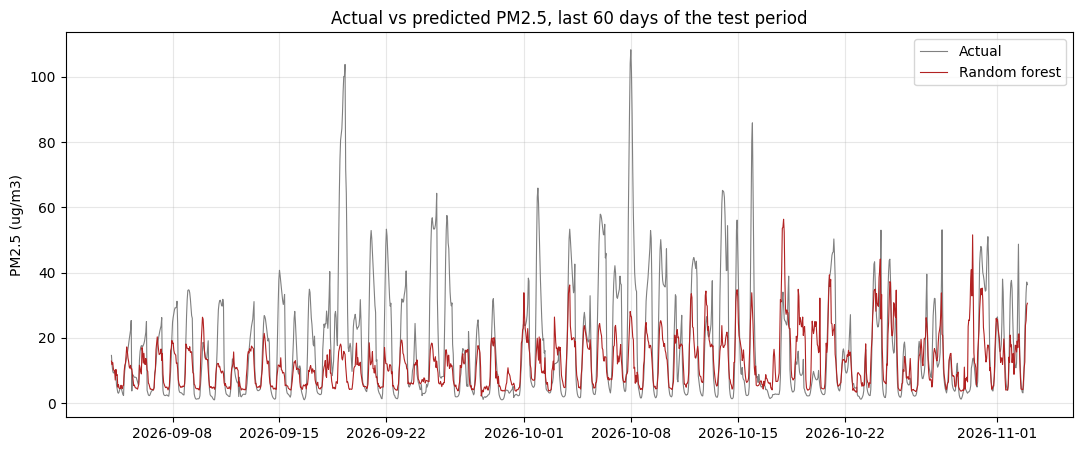

In [18]:
last = test.tail(24 * 60)
plt.figure(figsize=(13, 5))
plt.plot(last["time"], last["pm25"], color="gray", linewidth=0.8, label="Actual")
plt.plot(last["time"], pred["Random forest"][-len(last):], color="firebrick", linewidth=0.8, label="Random forest")
plt.title("Actual vs predicted PM2.5, last 60 days of the test period")
plt.ylabel("PM2.5 (ug/m3)"); plt.legend(); plt.grid(alpha=0.3); plt.show()

## 8. The Advisor
### 8a. Latest air quality in the data
Change `ACTIVITY` to see advice for different people. This is general guidance, not medical advice.

In [19]:
ADVICE = {
    "Good": "Great air. Go outside normally.",
    "Moderate": "Fine for most people. People with asthma or heart problems should avoid long, hard exercise outside.",
    "Unhealthy for sensitive": "Sensitive people should stay inside. Everyone else should shorten hard exercise outside. Wear an N95/KN95 mask for a long time outside.",
    "Unhealthy": "Avoid exercise outside. Wear an N95/KN95 mask when you go out. Use an air purifier indoors if you have one.",
    "Very unhealthy": "Stay inside as much as possible with the windows closed. Wear an N95/KN95 mask if you must go out.",
    "Hazardous": "Stay inside. Wear an N95/KN95 mask if you must go out. Take care of children and older people.",
}

def category_of(pm):
    return pd.cut([pm], PM_BINS, labels=CATS)[0]

def advise(pm, activity):
    cat = category_of(pm)
    # exercise and children breathe more air per body size, so we use one level stricter advice
    if activity in ("running / exercise", "kids playing outside"):
        shift = min(CATS.index(cat) + 1, len(CATS) - 1)
        return cat, CATS[shift], ADVICE[CATS[shift]]
    return cat, cat, ADVICE[cat]

# ---------------- SETTINGS ----------------
ACTIVITY = "walking"      # "walking", "running / exercise", or "kids playing outside"
# ------------------------------------------

latest = data[data["time"] > data["time"].max() - pd.Timedelta(hours=24)]
pm_now = latest["pm25"].mean()
cat, used, text = advise(pm_now, ACTIVITY)

print("Latest 24 hours in the data (ending %s)" % data["time"].max())
print("Average PM2.5: %.1f ug/m3 (WHO guideline is %d)" % (pm_now, WHO_DAILY))
print("Category:", cat)
print("Advice for", ACTIVITY + ":", text)

Latest 24 hours in the data (ending 2026-11-02 23:00:00)
Average PM2.5: 18.9 ug/m3 (WHO guideline is 15)
Category: Moderate
Advice for walking: Fine for most people. People with asthma or heart problems should avoid long, hard exercise outside.


### 8b. What if it is cold and calm? (simulator)
The random forest predicts PM2.5 for weather you choose. Change the numbers and run the cell again.

In [20]:
# ---------------- SETTINGS ----------------
WHATIF_TEMP = -25         # temperature in C
WHATIF_WIND = 2           # wind speed in km/h
WHATIF_HUMIDITY = 70      # %
WHATIF_HOUR = 8           # hour of the day, 0-23
WHATIF_HEATING = True     # heating season (Oct-Apr)?
# ------------------------------------------

row = pd.DataFrame([{
    "temp_c": WHATIF_TEMP, "wind_kmh": WHATIF_WIND, "humidity": WHATIF_HUMIDITY, "precipitation": 0,
    "is_heating": int(WHATIF_HEATING),
    "hour_sin": np.sin(2 * np.pi * WHATIF_HOUR / 24), "hour_cos": np.cos(2 * np.pi * WHATIF_HOUR / 24)}])
pm_pred = float(np.expm1(rf.predict(row[FEATURES]))[0])
cat, used, text = advise(pm_pred, "walking")

print("Weather: %s C, wind %s km/h, humidity %s%%, hour %s" % (WHATIF_TEMP, WHATIF_WIND, WHATIF_HUMIDITY, WHATIF_HOUR))
print("Predicted PM2.5: %.0f ug/m3 (%.1f times the WHO guideline)" % (pm_pred, pm_pred / WHO_DAILY))
print("Category:", cat)
print("Advice:", text)

Weather: -25 C, wind 2 km/h, humidity 70%, hour 8
Predicted PM2.5: 51 ug/m3 (3.4 times the WHO guideline)
Category: Unhealthy for sensitive
Advice: Sensitive people should stay inside. Everyone else should shorten hard exercise outside. Wear an N95/KN95 mask for a long time outside.


## 9. Findings
*Replace the text below with your own results after you run the notebook.*

1. The average PM2.5 is ___ in the heating season and ___ outside it, so the heating season is about ___ times worse.
2. The worst month is ___ and the worst hours of the day are around ___.
3. About ___% of days are above the WHO guideline and ___% are Unhealthy or worse.
4. Colder days have more pollution: each 10 C colder adds about ___ ug/m3 (correlation ___). Wind (does / does not) clean the air: PM2.5 is ___ when the wind is below 5 km/h and ___ when it is above 20 km/h.
5. The random forest predicts PM2.5 with an average error of ___ ug/m3 (R2 = ___), better than the baseline of ___. The most important feature is ___.
6. Over the years, the heating season average went from ___ to ___.

## 10. About the data and limits
- **Air quality source:** Open-Meteo Air Quality API, based on CAMS (Copernicus Atmosphere Monitoring Service) model data. https://open-meteo.com/en/docs/air-quality-api
- **Weather source:** Open-Meteo Historical Weather API, based on ERA5 reanalysis (Copernicus / ECMWF). https://open-meteo.com/en/docs/historical-weather-api
- **License:** Open-Meteo data is free for non-commercial use under CC BY 4.0. Please credit Open-Meteo.
- **Cleaning:** parsed the dates, removed duplicate hours and impossible values, filled short weather gaps, merged both sources on the hour, kept days with at least 18 hours of data for the daily table.
- **Limits:**
  - The air quality values are model estimates for a large grid cell, not readings from a sensor in a specific district. They can be lower than real readings in the ger districts. A real station (for example from OpenAQ) would be a good way to check them.
  - The heating season is assumed to be October to April.
  - The model uses weather only. It does not know about traffic, fuel use or other sources, so it cannot predict every spike.
  - The health advice is general and is not medical advice.